<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Trial 3 Complete [00h 01m 03s]
val_accuracy: 0.7406666874885559

Best val_accuracy So Far: 0.7633333206176758
Total elapsed time: 00h 02m 30s

Best Hyperparameters for GRU:
  Embedding Dim : 64
  Num Layers    : 1
  Units         : 32
  Dropout       : 0.4
  Learning Rate : 0.003

=== Best Model Comparison (SimpleRNN vs LSTM vs GRU) ===
Cell Type  Embed Dim  Layers  Units  Dropout    LR  Test Acc (%)  Parameters  Train Time (s)
SimpleRNN         64       1     32      0.2 0.003          56.5      643137           22.28
     LSTM         32       1     32      0.4 0.001          69.4      328353           31.29
      GRU         64       1     32      0.4 0.003          73.1      649441           38.44


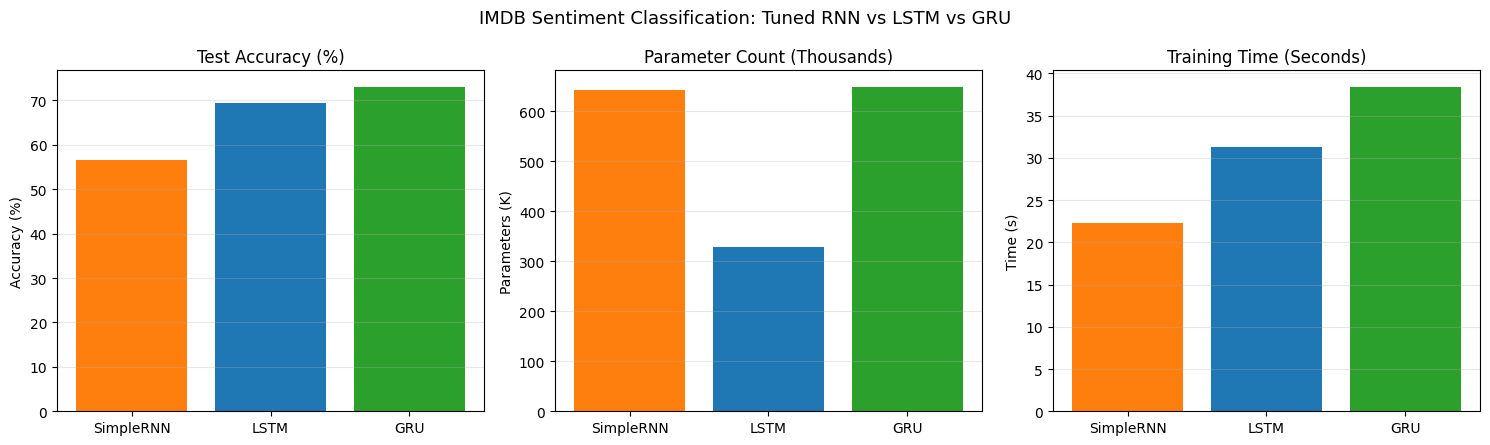

In [ ]:
!pip install -q keras-tuner

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner as kt

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Task 1: Load, Tokenise (Pre-indexed IMDB) & Pad Reviews
# ==========================================
VOCAB_SIZE = 10000
MAX_LEN = 100

(X_train_all, y_train_all), (X_test_all, y_test_all) = keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)

# Subset for fast tuning within a fixed Colab compute budget
X_train = keras.preprocessing.sequence.pad_sequences(X_train_all[:6000], maxlen=MAX_LEN, padding="post", truncating="post")
y_train = y_train_all[:6000]
X_val   = keras.preprocessing.sequence.pad_sequences(X_train_all[6000:7500], maxlen=MAX_LEN, padding="post", truncating="post")
y_val   = y_train_all[6000:7500]
X_test  = keras.preprocessing.sequence.pad_sequences(X_test_all[:2000], maxlen=MAX_LEN, padding="post", truncating="post")
y_test  = y_test_all[:2000]

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}\n")

# ==========================================
# Task 2: Model-Builder Function Choosing Cell Type (RNN, LSTM, GRU)
# ==========================================
def get_model_builder(cell_type):
    def build_model(hp):
        embed_dim  = hp.Choice("embedding_dim", values=[32, 64])
        num_layers = hp.Int("num_layers", min_value=1, max_value=2)
        units      = hp.Choice("units", values=[32, 64])
        dropout    = hp.Choice("dropout", values=[0.2, 0.4])
        lr         = hp.Choice("learning_rate", values=[1e-3, 3e-3])

        rnn_map = {
            "SimpleRNN": layers.SimpleRNN,
            "LSTM": layers.LSTM,
            "GRU": layers.GRU
        }
        RNNLayer = rnn_map[cell_type]

        model = keras.Sequential([
            layers.Input(shape=(MAX_LEN,)),
            layers.Embedding(input_dim=VOCAB_SIZE, output_dim=embed_dim)
        ])

        for i in range(num_layers):
            return_seq = (i < num_layers - 1)
            model.add(RNNLayer(units, return_sequences=return_seq))
            model.add(layers.Dropout(dropout))

        model.add(layers.Dense(1, activation="sigmoid"))
        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=lr),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )
        return model
    return build_model

# ==========================================
# Task 3 & 4: Tune Each Cell Type with KerasTuner & Report Best Config
# ==========================================
cell_types = ["SimpleRNN", "LSTM", "GRU"]
comparison_rows = []
best_histories = {}

for cell in cell_types:
    print(f"\n================ Tuning {cell} ================")
    tuner = kt.RandomSearch(
        get_model_builder(cell),
        objective="val_accuracy",
        max_trials=3,
        executions_per_trial=1,
        directory="kt_imdb_tuning",
        project_name=f"imdb_{cell.lower()}",
        overwrite=True
    )

    tuner.search(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=4,
        batch_size=64,
        verbose=1
    )

    best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
    print(f"\nBest Hyperparameters for {cell}:")
    print(f"  Embedding Dim : {best_hp.get('embedding_dim')}")
    print(f"  Num Layers    : {best_hp.get('num_layers')}")
    print(f"  Units         : {best_hp.get('units')}")
    print(f"  Dropout       : {best_hp.get('dropout')}")
    print(f"  Learning Rate : {best_hp.get('learning_rate')}")

    # Retrain best model to measure clean training time & test accuracy
    tf.random.set_seed(42)
    best_model = tuner.hypermodel.build(best_hp)
    start = time.time()
    hist = best_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=5,
        batch_size=64,
        verbose=0
    )
    train_time = time.time() - start
    _, test_acc = best_model.evaluate(X_test, y_test, verbose=0)

    best_histories[cell] = hist
    comparison_rows.append({
        "Cell Type": cell,
        "Embed Dim": best_hp.get("embedding_dim"),
        "Layers": best_hp.get("num_layers"),
        "Units": best_hp.get("units"),
        "Dropout": best_hp.get("dropout"),
        "LR": best_hp.get("learning_rate"),
        "Test Acc (%)": round(test_acc * 100, 2),
        "Parameters": best_model.count_params(),
        "Train Time (s)": round(train_time, 2)
    })

# ==========================================
# Task 5: Compare Accuracy, Parameter Count & Training Time
# ==========================================
results_df = pd.DataFrame(comparison_rows)
print("\n=== Best Model Comparison (SimpleRNN vs LSTM vs GRU) ===")
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = ["tab:orange", "tab:blue", "tab:green"]

axes[0].bar(results_df["Cell Type"], results_df["Test Acc (%)"], color=colors)
axes[0].set_title("Test Accuracy (%)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(results_df["Cell Type"], results_df["Parameters"] / 1e3, color=colors)
axes[1].set_title("Parameter Count (Thousands)")
axes[1].set_ylabel("Parameters (K)")
axes[1].grid(True, axis="y", alpha=0.3)

axes[2].bar(results_df["Cell Type"], results_df["Train Time (s)"], color=colors)
axes[2].set_title("Training Time (Seconds)")
axes[2].set_ylabel("Time (s)")
axes[2].grid(True, axis="y", alpha=0.3)

plt.suptitle("IMDB Sentiment Classification: Tuned RNN vs LSTM vs GRU", fontsize=13)
plt.tight_layout()
plt.show()